<a href="https://colab.research.google.com/github/prqshna-design/ML-mini-project-tasks/blob/main/task_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Regression Performance Table:
 K  Weights    MAE   RMSE    R2
 3  uniform 43.434 57.333 0.380
 3 distance 42.743 56.616 0.395
 5  uniform 42.778 55.204 0.425
 5 distance 42.157 54.760 0.434
 7  uniform 42.782 54.493 0.440
 7 distance 42.385 54.245 0.445
11  uniform 45.589 55.666 0.415
11 distance 44.716 54.983 0.429

Best model selected by cross-validation:
K: 11
Weights: distance
Best CV MAE: 47.772

Best model test performance:
MAE: 44.716
RMSE: 54.983
R2: 0.429


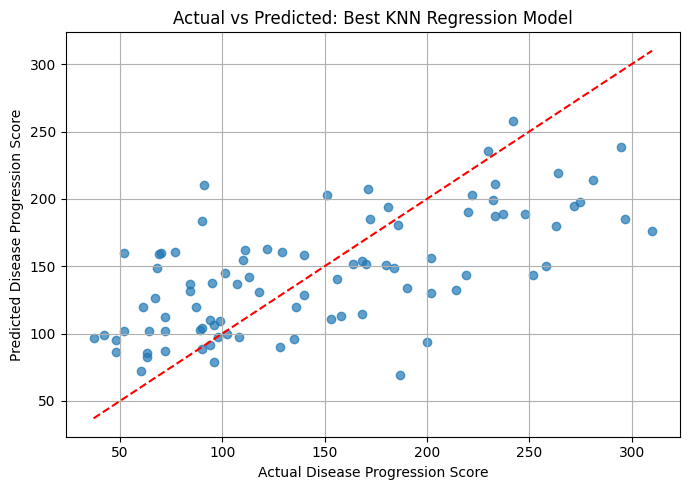


Five Largest Prediction Errors:
 Actual  Predicted  Absolute Error
  310.0    175.963         134.037
   91.0    209.960         118.960
  187.0     69.162         117.838
  297.0    184.782         112.218
  252.0    143.243         108.757


In [6]:

# Task 8: KNN Regression for Numerical Prediction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load and split the Diabetes dataset
diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Build a pipeline so scaling is fitted only on training data
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor())
])

# 2 & 3. Test K = 3, 5, 7, 11 with both weighting methods
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 11],
    "knn__weights": ["uniform", "distance"]
}

# 5. Select the best model using 5-fold cross-validation
# Choose the model with the lowest cross-validation MAE
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="neg_mean_absolute_error"
)

grid_search.fit(X_train, y_train)

# 4. Evaluate all configurations on the test set
results = []

for k in [3, 5, 7, 11]:
    for weight in ["uniform", "distance"]:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("knn", KNeighborsRegressor(
                n_neighbors=k, weights=weight
            ))
        ])

        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        mae = mean_absolute_error(y_test, predictions)
        rmse = np.sqrt(mean_squared_error(y_test, predictions))
        r2 = r2_score(y_test, predictions)

        results.append({
            "K": k,
            "Weights": weight,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

results_df = pd.DataFrame(results)

print("Regression Performance Table:")
print(results_df.round(3).to_string(index=False))

# Display the best cross-validation configuration
best_model = grid_search.best_estimator_
print("\nBest model selected by cross-validation:")
print("K:", grid_search.best_params_["knn__n_neighbors"])
print("Weights:", grid_search.best_params_["knn__weights"])
print("Best CV MAE:", round(-grid_search.best_score_, 3))

# Predict using the selected model
best_predictions = best_model.predict(X_test)

print("\nBest model test performance:")
print("MAE:", round(mean_absolute_error(y_test, best_predictions), 3))
print("RMSE:", round(np.sqrt(
    mean_squared_error(y_test, best_predictions)
), 3))
print("R2:", round(r2_score(y_test, best_predictions), 3))

# 6. Plot actual versus predicted values
plt.figure(figsize=(7, 5))
plt.scatter(y_test, best_predictions, alpha=0.7)

# Reference line: perfect predictions
lower = min(y_test.min(), best_predictions.min())
upper = max(y_test.max(), best_predictions.max())
plt.plot([lower, upper], [lower, upper], "r--")

plt.xlabel("Actual Disease Progression Score")
plt.ylabel("Predicted Disease Progression Score")
plt.title("Actual vs Predicted: Best KNN Regression Model")
plt.grid(True)
plt.tight_layout()
plt.show()

# 7. Analyze the five largest prediction errors
error_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": best_predictions,
    "Absolute Error": np.abs(y_test - best_predictions)
})

largest_errors = error_df.nlargest(5, "Absolute Error")

print("\nFive Largest Prediction Errors:")
print(largest_errors.round(3).to_string(index=False))
